# TMA azimuth encoder-head loss → mount impulse (MC_O_20261107_000069)

**Question.** A large impulse was seen in the mount, M2, M1M3 and both hexapods during LSSTCam exposure
**MC_O_20261107_000069** (ConsDB `obs_start` 2026-11-08T02:25:18.615 **TAI**). What caused it, what did it do to the
image, and how often does it happen?

**Data.** EFD (`usdf_efd`): `MTMount.azimuth/elevation/encoder/azimuthDrives/cameraCableWrap`, `MTMount.logevent_warning`,
`MTM2.tangentForce/axialForce/positionIMS`, `MTHexapod.actuators/application` (1 = camera, 2 = M2),
`MTM1M3.hardpointActuatorData/accelerometerData`, `MTRotator.rotation`, `ESS.accelerometer` (top-end, 200 Hz).
ConsDB: `cdb_lsstcam.exposure`, `visit1_quicklook` (PSF moments, guider drift). Caches are written by
[build_az_encoder_headloss.py](build_az_encoder_headloss.py) into `data/` (gitignored).

**Conventions.**
* EFD index times are **UTC**; ConsDB `obs_start`/`obs_end` are **TAI** (= UTC + 37 s). The quoted start time is TAI —
  the exposure actually integrated 02:24:41.6–02:25:12.5 UTC.
* MTMount sample timestamps (`actual*Timestamp`, `encoder*Timestamp`) are unix TAI and are used where sub-100 ms
  ordering matters; other subsystems are compared on their EFD stamps (publish latency tens of ms).
* Azimuth encoder heads: warning code **714/715/716/717 = head 1/2/3/4** (`TMA_AZ_ENC_AZM_000n`) =
  array index **0/1/2/3** in `MTMount.encoder` (`encoderHeadReadReferenceAZn` = 0 when the head is lost).

## Key findings (2026-11-09)

**The impulse in 20261107/69 was caused by the TMA itself: an azimuth encoder head dropped out mid-exposure. Removing
it from the position average made the reported azimuth jump 5″, and the servo kicked the axis to null an error that
was not real.**

| UTC 2026-11-08 | event |
|---|---|
| 02:13:32 | azimuth head 4 (`AZM_0004`) lost (warning 717) — axis continues on heads 1–3 |
| 02:24:41.6 | exposure 69 opens (ConsDB `obs_start` 02:25:18.615 is **TAI**) |
| **02:24:59.58** | **head 1 (`AZM_0001`) lost** (warning 714 at 59.629): reported azimuth jumps **−5.07″ in one 50 ms sample**, demand smooth |
| 02:24:59.58–.70 | servo responds: az torque **+142 kN m** (tracking ≈ 10 kN m), velocity 118″/s vs 45″/s tracking; overshoot +1.6″, settled in ≈ 0.4 s |
| after | axis sits **+5.4″ further in azimuth** as seen by the surviving heads 2+3 (≈ 1.3″ on sky at el 76°) — a permanent step until the next power cycle |
| 02:25:12.5 | exposure 69 closes; the axis then ran on **two heads** for the rest of the night and all of 20261108 (power cycle 2026-11-09 13:01) |

1. **Everything on the TMA felt it.** Within ~0.1 s of the jump: M1M3 hardpoints ±265 N (42× their scatter), M1M3
   angular acceleration Z 0.83 rad/s² (49×), M2 tangent links ±34 N (8×), camera- and M2-hexapod actuator following
   errors ≈ 0.85 µm (≈ 40×), rotator 1.2″ and camera cable wrap 2.9″ following error. Elevation torque is unaffected —
   the source is purely the azimuth axis.
2. **The image is damaged.** Guider azimuth drift **−1.80″** (neighbours ~0.1″), PSF ellipticity **0.45** (neighbours
   ≤ 0.08), FWHM 1.72″ vs ~1.47″, and only 7 PSF stars per detector vs ~30.
3. **That night azimuth was power-cycled three times** (22:02→23:51, 01:44→01:45, 02:07→02:10 UTC) and heads dropped
   out again within 10–35 min each time. 69 is the only loss that night that fell inside an exposure — and the only one
   that went from three heads to two.
4. **Head losses are chronic** — 577 real azimuth drop-outs since 2025-04, almost all on **head 4 (300)** and **head 1 (196)**.
5. **What changed is the consequence, not the rate.** For losses while tracking, the median kick was **1.9 kN m with a
   0.02″ jump through May 2026**, and **≈ 80 kN m with a 3.3–3.6″ jump since June 2026** (18 cases). Since June, **9 of 13
   losses inside exposures produced ≥ 0.5″ jumps, 8 confirmed by the guider (0.7–3.7″ drift)** — 20261107/69 is one of
   the largest. The onset (~2026-06-01) precedes the first MTMount CSC 0.33.5a0 deployment (06-13), so it points at the
   low-level TMA controller or the head calibration, not the CSC.

## Setup

In [1]:
import pathlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

DATA = pathlib.Path("data")
TAI_UTC = pd.Timedelta(seconds=37)
DAY_OBS, SEQ = 20261107, 69
AZ_HEAD = {714: 0, 715: 1, 716: 2, 717: 3}          # warning code -> encoder array index
HEAD_LABEL = {i: f"head {i + 1} (AZM_000{i + 1})" for i in range(4)}

# Plot style (reference palette, same as Louver_Drive_Health)
C_AZ, C_EL, C_GRAY, C_FAULT, C_WARN = "#2a78d6", "#eb6834", "#8a8984", "#e34948", "#eda100"
C6 = ["#2a78d6", "#eb6834", "#1f9e89", "#9b59b6", "#eda100", "#5c5b57"]
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "lines.linewidth": 1.4,
    "axes.prop_cycle": plt.cycler(color=C6),
})


def tai2utc(s):
    """ConsDB naive TAI timestamps -> tz-aware UTC."""
    return pd.to_datetime(s, format="ISO8601").dt.tz_localize("UTC") - TAI_UTC


def unix_tai(x):
    """MTMount unix-TAI sample timestamps -> tz-aware UTC."""
    return pd.to_datetime(np.asarray(x) - 37.0, unit="s", utc=True)


def fmt_t(ax, fmt="%H:%M:%S"):
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))

In [2]:
ev = {p.stem.replace("azenc_event_", ""): pd.read_parquet(p) for p in sorted(DATA.glob("azenc_event_*.parquet"))}
nexp = pd.read_parquet(DATA / "azenc_night_20261107_exposures.parquet")
nql = pd.read_parquet(DATA / "azenc_night_20261107_quicklook.parquet")
nref = pd.read_parquet(DATA / "azenc_night_20261107_refs.parquet")
ntq = pd.read_parquet(DATA / "azenc_night_20261107_aztorque.parquet")
warn = pd.read_parquet(DATA / "azenc_hist_warnings.parquet")
print("event topics:", ", ".join(ev))
print(f"night exposures: {len(nexp)}   warnings 700-719 since 2025-04: {len(warn)}")

event topics: ESS_accelerometer, MTCamera_logevent_endShutterClose, MTCamera_logevent_startIntegration, MTHexapod_actuators_1, MTHexapod_actuators_2, MTHexapod_application_1, MTHexapod_application_2, MTM1M3_accelerometerData, MTM1M3_hardpointActuatorData, MTM2_axialForce, MTM2_positionIMS, MTM2_tangentForce, MTMount_azimuth, MTMount_azimuthDrives, MTMount_cameraCableWrap, MTMount_elevation, MTMount_encoder, MTRotator_rotation
night exposures: 435   warnings 700-719 since 2025-04: 3150


## 1. Exposure timing — the quoted time is TAI

The exposure list from ConsDB is converted to UTC and checked against the camera's own `startIntegration` event.

In [3]:
nexp["t0"], nexp["t1"] = tai2utc(nexp.obs_start), tai2utc(nexp.obs_end)
nexp = nexp.set_index("seq_num")
E0, E1 = nexp.loc[SEQ, "t0"], nexp.loc[SEQ, "t1"]
si = ev["MTCamera_logevent_startIntegration"]
tab = nexp.loc[SEQ - 2:SEQ + 2, ["obs_start", "t0", "t1", "exp_time"]].rename(
    columns={"obs_start": "obs_start (TAI, ConsDB)", "t0": "start (UTC)", "t1": "end (UTC)"})
display(tab)
t_si = si.index[si.imageName.str.endswith(f"{DAY_OBS}_{SEQ:06d}")][0]
print(f"camera startIntegration (EFD, UTC) for seq {SEQ}: {t_si:%H:%M:%S.%f} — ConsDB obs_start − 37 s = {E0:%H:%M:%S.%f}")

w_ev = warn[(warn.index > E0 - pd.Timedelta("60s")) & (warn.index < E1 + pd.Timedelta("60s"))]
display(w_ev)
LOSS = w_ev[w_ev.code == 714].index[0]
print(f"warning 714 at {LOSS:%H:%M:%S.%f} UTC = {(LOSS - E0).total_seconds():.1f} s into the "
      f"{(E1 - E0).total_seconds():.1f} s exposure {DAY_OBS}/{SEQ}")

,"obs_start (TAI, ConsDB)",start (UTC),end (UTC),exp_time
seq_num,,,,
67,2026-11-08T02:22:17.852000,2026-11-08 02:21:40.852000+00:00,2026-11-08 02:22:11.782000+00:00,30.0
68,2026-11-08T02:22:52.447000,2026-11-08 02:22:15.447000+00:00,2026-11-08 02:22:46.376000+00:00,30.0
69,2026-11-08T02:25:18.615000,2026-11-08 02:24:41.615000+00:00,2026-11-08 02:25:12.546000+00:00,30.0
70,2026-11-08T02:25:56.375000,2026-11-08 02:25:19.375000+00:00,2026-11-08 02:25:50.305000+00:00,30.0
71,2026-11-08T02:29:50.237000,2026-11-08 02:29:13.237000+00:00,2026-11-08 02:29:52.167000+00:00,38.0


camera startIntegration (EFD, UTC) for seq 69: 02:24:41.620927 — ConsDB obs_start − 37 s = 02:24:41.615000


,active,code,text
2026-11-08 02:24:59.628898+00:00,True,714,"The azimuth encoder head 1, TMA_AZ_ENC_AZM_000..."


warning 714 at 02:24:59.628898 UTC = 18.0 s into the 30.9 s exposure 20261107/69


## 2. Overview — one impulse, mid-exposure, while tracking

Two minutes of telemetry around exposure 69 (shaded). The large excursions at the edges are the slews before and after
exposure 69 (and a small offset slew between 69 and 70). The **vertical red line** is the encoder-head-loss warning.

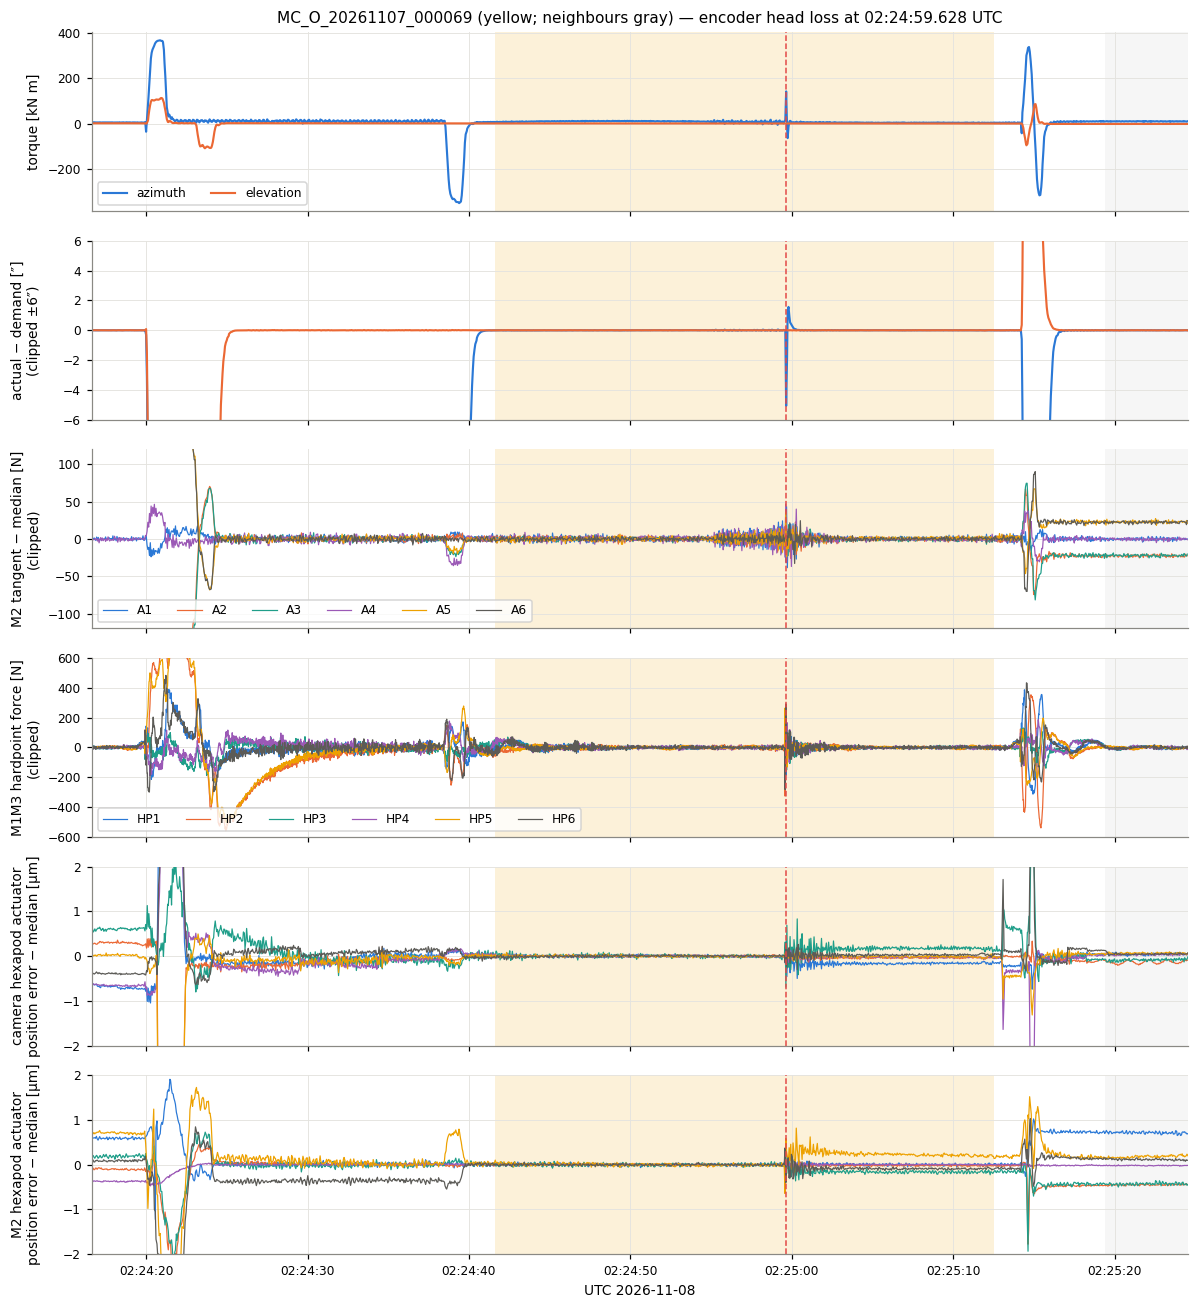

In [4]:
az, el = ev["MTMount_azimuth"], ev["MTMount_elevation"]
m2t, hp = ev["MTM2_tangentForce"], ev["MTM1M3_hardpointActuatorData"]
a1, a2 = ev["MTHexapod_actuators_1"], ev["MTHexapod_actuators_2"]
X0, X1 = E0 - pd.Timedelta("25s"), E1 + pd.Timedelta("12s")
cut = lambda d: d[(d.index > X0) & (d.index < X1)]

fig, ax = plt.subplots(6, 1, figsize=(11, 12), sharex=True)
ax[0].plot(cut(az).index, cut(az).actualTorque / 1e3, color=C_AZ, label="azimuth")
ax[0].plot(cut(el).index, cut(el).actualTorque / 1e3, color=C_EL, label="elevation")
ax[0].set_ylabel("torque [kN m]"); ax[0].legend(loc="lower left", ncol=2)
ax[1].plot(cut(az).index, (cut(az).actualPosition - cut(az).demandPosition) * 3600, color=C_AZ, label="azimuth")
ax[1].plot(cut(el).index, (cut(el).actualPosition - cut(el).demandPosition) * 3600, color=C_EL, label="elevation")
ax[1].set_ylim(-6, 6); ax[1].set_ylabel("actual − demand [″]\n(clipped ±6″)")
for i in range(6):
    s = cut(m2t)[f"measured{i}"]; ax[2].plot(s.index, s - s[(s.index > E0) & (s.index < LOSS)].median(), lw=0.8, label=f"A{i + 1}")
ax[2].set_ylim(-120, 120); ax[2].set_ylabel("M2 tangent − median [N]\n(clipped)"); ax[2].legend(ncol=6, loc="lower left")
for i in range(6):
    ax[3].plot(cut(hp).index, cut(hp)[f"measuredForce{i}"], lw=0.8, label=f"HP{i + 1}")
ax[3].set_ylim(-600, 600); ax[3].set_ylabel("M1M3 hardpoint force [N]\n(clipped)"); ax[3].legend(ncol=6, loc="lower left")
for k, (a, nm) in enumerate(((a1, "camera"), (a2, "M2"))):
    for i in range(6):
        s = cut(a)[f"positionError{i}"]; ax[4 + k].plot(s.index, s - s[(s.index > E0) & (s.index < LOSS)].median(), lw=0.8)
    ax[4 + k].set_ylim(-2, 2); ax[4 + k].set_ylabel(f"{nm} hexapod actuator\nposition error − median [µm]")
for a in ax:
    for s in (SEQ - 1, SEQ, SEQ + 1):
        a.axvspan(nexp.loc[s, "t0"], nexp.loc[s, "t1"], color=C_WARN if s == SEQ else C_GRAY, alpha=0.15 if s == SEQ else 0.07, lw=0)
    a.axvline(LOSS, color=C_FAULT, lw=1, ls="--")
ax[0].set_title(f"MC_O_{DAY_OBS}_{SEQ:06d} (yellow; neighbours gray) — encoder head loss at {LOSS:%H:%M:%S.%f}"[:-3] + " UTC")
ax[-1].set_xlim(X0, X1); fmt_t(ax[-1]); ax[-1].set_xlabel("UTC 2026-11-08")
fig.align_ylabels(); plt.tight_layout(); plt.show()

## 3. Mechanism — losing a head moved the *reported* azimuth by −5″, the servo then really moved the mount

The azimuth position is formed from the encoder heads that still have a valid read reference. At the moment head 1
dropped out, head 4 had already been lost (since 02:13:32), so the axis went from **three heads to two**.

Below, the mount's own sample clock (unix TAI) is used. The **reported** position jumps in one 50 ms sample while the
demand is smooth; the velocity estimate goes the *other* way (positive) — i.e. there was no physical −5″ motion, the
controller saw a position error and kicked the axis to null it.

In [5]:
azs = az.copy()
azs["t"] = unix_tai(azs.actualPositionTimestamp)
azs = azs.set_index("t").sort_index()
azs["err_as"] = (azs.actualPosition - azs.demandPosition) * 3600
T_JUMP = azs.index[(azs.index > LOSS - pd.Timedelta("1s")) & (azs.err_as.abs() > 1)][0]   # first mount sample with |err| > 1″
print(f"first mount sample with |az error| > 1″: {T_JUMP:%H:%M:%S.%f} UTC "
      f"({(T_JUMP - LOSS).total_seconds() * 1e3:+.0f} ms vs. the EFD stamp of warning 714)")
w = azs[(azs.index > LOSS - pd.Timedelta("0.15s")) & (azs.index < LOSS + pd.Timedelta("0.40s"))]
tbl = pd.DataFrame({"az actual − demand [″]": w.err_as.round(2), "az torque [kN m]": (w.actualTorque / 1e3).round(1),
                    "az velocity [″/s]": (w.actualVelocity * 3600).round(1), "demand velocity [″/s]": (w.demandVelocity * 3600).round(1)})
tbl.index = tbl.index.strftime("%H:%M:%S.%f").str[:-3]
display(tbl)

first mount sample with |az error| > 1″: 02:24:59.582649 UTC (-46 ms vs. the EFD stamp of warning 714)


,az actual − demand [″],az torque [kN m],az velocity [″/s],demand velocity [″/s]
t,,,,
02:24:59.482,0.00,11.6,38.2,45.1
02:24:59.532,-0.03,16.1,39.3,45.1
02:24:59.582,-5.07,142.0,85.5,45.1
02:24:59.634,-1.81,-14.3,117.6,45.1
02:24:59.682,1.33,-62.8,72.9,45.1
02:24:59.732,1.57,-13.6,42.5,45.1
02:24:59.782,0.93,9.8,36.3,45.1
02:24:59.832,0.53,13.0,42.0,45.1
02:24:59.882,0.41,9.0,40.3,45.1


In [6]:
enc = ev["MTMount_encoder"].copy()
enc["t"] = unix_tai(enc.azimuthEncoderAbsolutePositionTimestamp1)
enc = enc.set_index("t").sort_index()
for i in range(4):
    enc[f"u{i}"] = np.rad2deg(np.unwrap(np.deg2rad(enc[f"azimuthEncoderAbsolutePosition{i}"])))
valid = pd.DataFrame({HEAD_LABEL[i]: enc[f"encoderHeadReadReferenceAZ{i}"] != 0 for i in range(4)})
before = valid[valid.index < LOSS - pd.Timedelta("0.2s")].iloc[-1]
after = valid[valid.index > LOSS + pd.Timedelta("0.2s")].iloc[0]
display(pd.DataFrame({"valid before": before, "valid after": after}))

m12 = (enc.u1 + enc.u2) / 2                                  # heads 2 and 3 are good throughout
act = np.interp(enc.index.asi8, azs.index.asi8, azs.actualPosition.to_numpy())
dem = np.interp(enc.index.asi8, azs.index.asi8, azs.demandPosition.to_numpy())
enc["rep_minus_h23"] = (act - m12) * 3600                   # reported position relative to heads 2+3
enc["dem_minus_h23"] = (dem - m12) * 3600
pre = (enc.index > LOSS - pd.Timedelta("5s")) & (enc.index < LOSS - pd.Timedelta("0.1s"))   # tracking only
post = (enc.index > LOSS + pd.Timedelta("1.0s")) & (enc.index < LOSS + pd.Timedelta("5s"))
STEP = enc.rep_minus_h23[post].median() - enc.rep_minus_h23[pre].median()
h1_off = ((enc.u0 - m12) * 3600)[pre].median()
EL_DEG = el.actualPosition[(el.index > E0) & (el.index < E1)].mean()
print(f"reported azimuth relative to heads 2+3: step {STEP:+.2f}″ (permanent; scatter {enc.rep_minus_h23[pre].std():.2f}″)")
print(f"raw head-1 reading relative to heads 2+3 before the loss: {h1_off:+.1f}″ "
      f"(a mean over heads 1-3 shifts by −1/3 of the calibrated offset → implied calibrated offset ≈ {-3 * STEP:+.1f}″)")
print(f"elevation {EL_DEG:.2f}° → on-sky azimuth step ≈ {abs(STEP) * np.cos(np.deg2rad(EL_DEG)):.2f}″")

,valid before,valid after
head 1 (AZM_0001),True,False
head 2 (AZM_0002),True,True
head 3 (AZM_0003),True,True
head 4 (AZM_0004),False,False


reported azimuth relative to heads 2+3: step -5.41″ (permanent; scatter 0.35″)
raw head-1 reading relative to heads 2+3 before the loss: +19.1″ (a mean over heads 1-3 shifts by −1/3 of the calibrated offset → implied calibrated offset ≈ +16.2″)
elevation 76.34° → on-sky azimuth step ≈ 1.28″


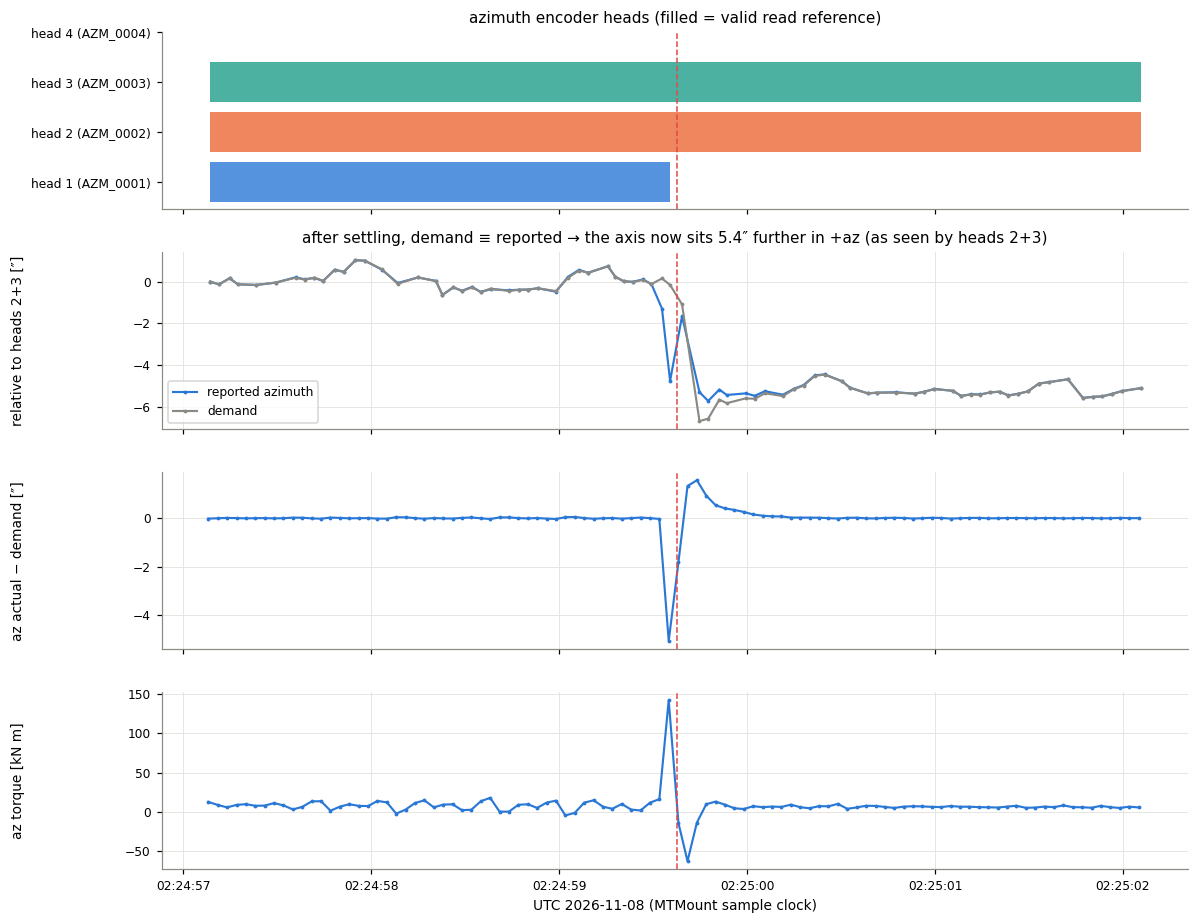

In [7]:
Z0, Z1 = LOSS - pd.Timedelta("2.5s"), LOSS + pd.Timedelta("2.5s")
zc = lambda d: d[(d.index > Z0) & (d.index < Z1)]
fig, ax = plt.subplots(4, 1, figsize=(11, 8.5), sharex=True)
for i in range(4):
    v = zc(valid)[HEAD_LABEL[i]]
    ax[0].fill_between(v.index, i, i + 0.8 * v.astype(int), step="post", color=C6[i], alpha=0.8, lw=0)
ax[0].set_yticks(np.arange(4) + 0.4, [HEAD_LABEL[i] for i in range(4)]); ax[0].set_title("azimuth encoder heads (filled = valid read reference)")
ax[0].grid(False)
z = zc(enc)
ax[1].plot(z.index, z.rep_minus_h23 - enc.rep_minus_h23[pre].median(), ".-", ms=3, color=C_AZ, label="reported azimuth")
ax[1].plot(z.index, z.dem_minus_h23 - enc.rep_minus_h23[pre].median(), ".-", ms=3, color=C_GRAY, label="demand")
ax[1].set_ylabel("relative to heads 2+3 [″]"); ax[1].legend(loc="lower left")
ax[1].set_title("after settling, demand ≡ reported → the axis now sits 5.4″ further in +az (as seen by heads 2+3)")
z = zc(azs)
ax[2].plot(z.index, z.err_as, ".-", ms=3, color=C_AZ); ax[2].set_ylabel("az actual − demand [″]")
ax[3].plot(z.index, z.actualTorque / 1e3, ".-", ms=3, color=C_AZ); ax[3].set_ylabel("az torque [kN m]")
for a in ax:
    a.axvline(LOSS, color=C_FAULT, lw=1, ls="--")
fmt_t(ax[-1]); ax[-1].set_xlabel("UTC 2026-11-08 (MTMount sample clock)")
fig.align_ylabels(); plt.tight_layout(); plt.show()

In [8]:
drv = ev["MTMount_azimuthDrives"]
dz = drv[(drv.index > LOSS - pd.Timedelta("1s")) & (drv.index < LOSS + pd.Timedelta("1s"))]
cur = dz[[f"current{i}" for i in range(16)]]
print("azimuth drive currents (16 drives): pre-loss median |I| = %.1f A, peak |I| within ±1 s = %.1f A; "
      "all drives peak in the same sample: %s" % (cur[cur.index < LOSS].abs().median().median(), cur.abs().max().max(),
                                                cur.abs().idxmax().nunique() <= 2))

azimuth drive currents (16 drives): pre-loss median |I| = 0.1 A, peak |I| within ±1 s = 2.1 A; all drives peak in the same sample: True


## 4. Downstream response — everything on the TMA felt the kick

Peak deviation from the pre-event level (median over 2 s before the jump) in the 1.5 s after it, compared with the
pre-event scatter. `t_peak` is relative to the first mount sample of the position jump (`T_JUMP`, MTMount sample clock);
other subsystems are on EFD stamps, so a few tens of ms of publish latency apply.

In [9]:
P0, P1 = T_JUMP - pd.Timedelta("2s"), T_JUMP - pd.Timedelta("0.15s")
Q0, Q1 = T_JUMP - pd.Timedelta("0.15s"), T_JUMP + pd.Timedelta("1.5s")
acc, rot, ccw = ev["MTM1M3_accelerometerData"], ev["MTRotator_rotation"], ev["MTMount_cameraCableWrap"]
m2p = ev["MTM2_positionIMS"]
series = {
    "mount az torque [kN m]": az.actualTorque / 1e3,
    "mount az actual−demand [″]": (az.actualPosition - az.demandPosition) * 3600,
    "mount el torque [kN m]": el.actualTorque / 1e3,
    **{f"M1M3 HP{i + 1} force [N]": hp[f"measuredForce{i}"] for i in range(6)},
    **{f"M1M3 ang. accel {c}": acc[f"angularAcceleration{c}"] for c in "XYZ"},
    **{f"M2 tangent A{i + 1} [N]": m2t[f"measured{i}"] for i in range(6)},
    **{f"camera hexapod act{i + 1} pos err [µm]": a1[f"positionError{i}"] for i in range(6)},
    **{f"M2 hexapod act{i + 1} pos err [µm]": a2[f"positionError{i}"] for i in range(6)},
    "rotator actual−demand [″]": (rot.actualPosition - rot.demandPosition) * 3600,
    "camera cable wrap actual−demand [″]": (ccw.actualPosition - ccw.demandPosition) * 3600,
}
rows = []
for nm, s in series.items():
    p, q = s[(s.index > P0) & (s.index < P1)], s[(s.index > Q0) & (s.index < Q1)]
    dev = (q - p.median()).abs()
    rms = p.std()
    rows.append(dict(signal=nm, pre_rms=p.std(), peak_dev=dev.max(), ratio=dev.max() / rms,
                     t_peak=f"{(dev.idxmax() - T_JUMP).total_seconds() * 1e3:+.0f} ms"))
resp = pd.DataFrame(rows).set_index("signal")
resp["group"] = resp.index.str.extract(r"^(mount az actual|mount az torque|mount el|M1M3 HP|M1M3 ang|M2 tangent|camera hexapod|M2 hexapod|rotator|camera cable)", expand=False).values
print("largest response per subsystem (ratio = peak deviation / pre-event rms):")
display(resp.sort_values("ratio", ascending=False).groupby("group", sort=False).head(1)[["pre_rms", "peak_dev", "ratio", "t_peak"]].round(2))

largest response per subsystem (ratio = peak deviation / pre-event rms):


,pre_rms,peak_dev,ratio,t_peak
signal,,,,
mount az actual−demand [″],0.02,5.07,231.45,+68 ms
M1M3 ang. accel Z,0.02,0.83,49.02,-26 ms
M1M3 HP5 force [N],6.36,264.81,41.62,-6 ms
M2 hexapod act5 pos err [µm],0.02,0.82,39.72,+694 ms
camera hexapod act3 pos err [µm],0.02,0.85,37.13,+754 ms
mount az torque [kN m],5.47,133.86,24.47,+68 ms
M2 tangent A6 [N],4.25,33.52,7.90,+594 ms
mount el torque [kN m],0.04,0.22,5.74,+718 ms
rotator actual−demand [″],0.50,1.18,2.37,+47 ms


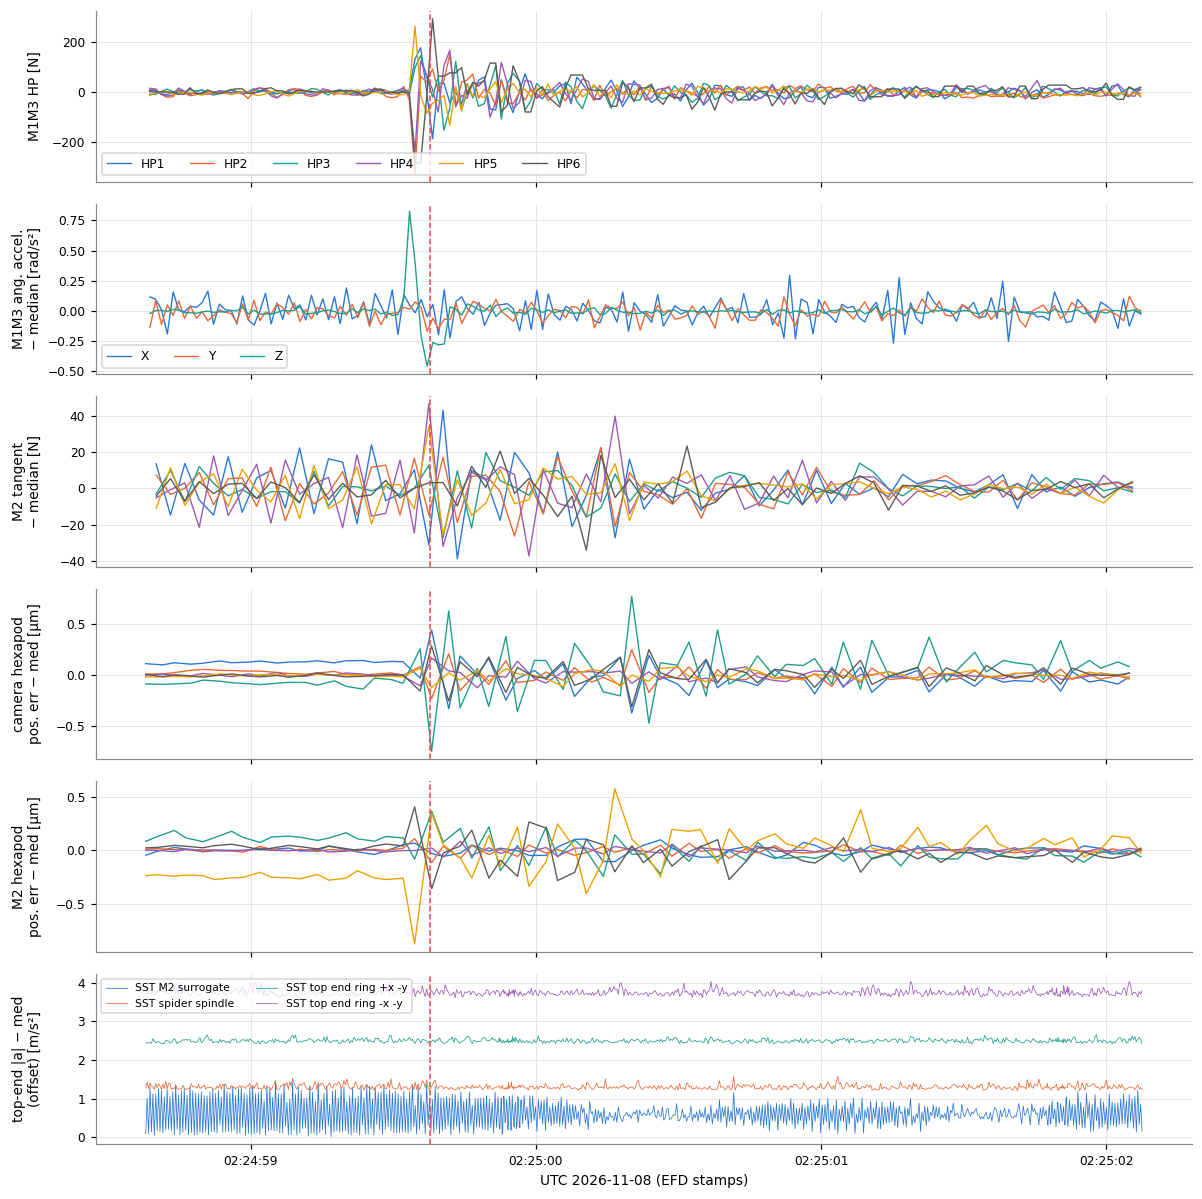

In [10]:
Z0, Z1 = LOSS - pd.Timedelta("1s"), LOSS + pd.Timedelta("2.5s")
zc = lambda d: d[(d.index > Z0) & (d.index < Z1)]
ess = ev["ESS_accelerometer"]
fig, ax = plt.subplots(6, 1, figsize=(11, 11), sharex=True)
for i in range(6):
    ax[0].plot(zc(hp).index, zc(hp)[f"measuredForce{i}"], lw=0.9, label=f"HP{i + 1}")
ax[0].set_ylabel("M1M3 HP [N]"); ax[0].legend(ncol=6, loc="lower left")
for c in "XYZ":
    ax[1].plot(zc(acc).index, zc(acc)[f"angularAcceleration{c}"] - acc[f"angularAcceleration{c}"].median(), lw=0.9, label=c)
ax[1].set_ylabel("M1M3 ang. accel.\n− median [rad/s²]"); ax[1].legend(ncol=3, loc="lower left")
for i in range(6):
    s = zc(m2t)[f"measured{i}"]; ax[2].plot(s.index, s - s.median(), lw=0.9, label=f"A{i + 1}")
ax[2].set_ylabel("M2 tangent\n− median [N]")
for k, (a, nm) in enumerate(((a1, "camera"), (a2, "M2"))):
    for i in range(6):
        s = zc(a)[f"positionError{i}"]; ax[3 + k].plot(s.index, s - s.median(), lw=0.9)
    ax[3 + k].set_ylabel(f"{nm} hexapod\npos. err − med [µm]")
for k, (nm, g) in enumerate(ess.groupby("sensor")):
    g = zc(g); mag = np.sqrt(((g[list("XYZ")] - g[list("XYZ")].median()) ** 2).sum(axis=1))
    ax[5].plot(mag.index, mag + 1.2 * k, lw=0.5, label=nm)
ax[5].set_ylabel("top-end |a| − med\n(offset) [m/s²]"); ax[5].legend(ncol=2, loc="upper left", fontsize=7)
for a in ax:
    a.axvline(LOSS, color=C_FAULT, lw=1, ls="--")
fmt_t(ax[-1]); ax[-1].set_xlabel("UTC 2026-11-08 (EFD stamps)")
fig.align_ylabels(); plt.tight_layout(); plt.show()

The 200 Hz top-end accelerometers (`ESS:104`) do not show a clear spike: their packets have gaps at the event and the
"SST M2 surrogate" channel carries a ±1 m/s² beat throughout. The impulse is dominated by the azimuth axis
(torque, hardpoints, M2 tangent links, rotator and cable-wrap following error); elevation torque is unaffected.

## 5. Image impact — ConsDB quicklook and guider

A 5.4″ azimuth step at elevation ≈76° is ≈1.3″ on sky, applied ~18 s into a 30 s exposure: stars are doubled /
elongated along azimuth.

,band,exp_time,psf_fwhm_as,psf_e,psf_ixy_median,n_psf_star_median,guider_azimuth_drift,guider_azimuth_standard_deviation,guider_altitude_drift,guider_n_tracked_stars
seq_num,,,,,,,,,,
60,r,30.000000,2.098000,0.266000,-1.140000,0,-0.025000,0.092000,-0.381000,1.000000
61,r,30.000000,1.800000,0.167000,-0.736000,26,-0.074000,0.073000,-0.143000,2.000000
62,r,30.000000,1.863000,0.102000,-0.820000,26,0.019000,0.064000,0.006000,1.000000
63,r,30.000000,1.879000,0.082000,-1.130000,26,-0.196000,0.087000,-0.104000,2.000000
64,r,30.000000,1.917000,0.128000,-1.044000,26,0.059000,0.095000,-0.228000,2.000000
65,r,30.000000,1.459000,0.066000,-0.355000,31,nan,nan,nan,nan
66,r,30.000000,1.446000,0.056000,-0.388000,31,nan,nan,nan,nan
67,r,30.000000,1.356000,0.047000,0.025000,33,-0.075000,0.067000,-0.141000,2.000000
68,r,30.000000,1.492000,0.034000,-0.223000,30,-0.109000,0.071000,0.084000,2.000000


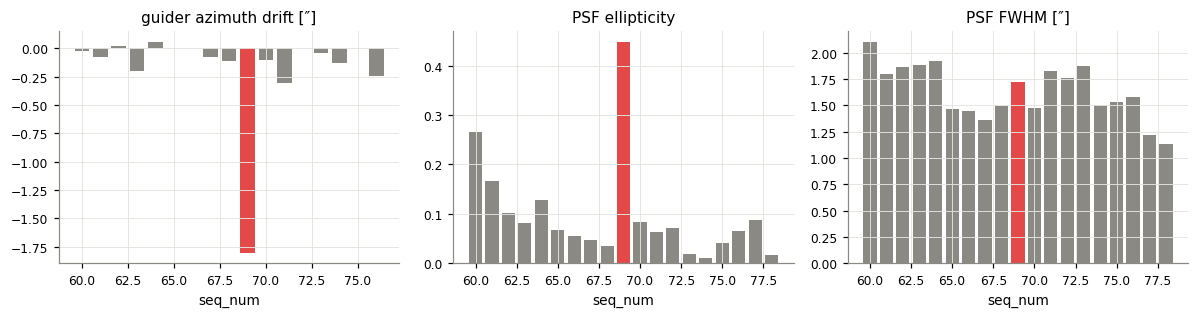

In [11]:
q = nql.set_index("seq_num").sort_index().loc[SEQ - 9:SEQ + 9].copy()
q["psf_e"] = np.hypot(q.psf_ixx_median - q.psf_iyy_median, 2 * q.psf_ixy_median) / (q.psf_ixx_median + q.psf_iyy_median)
q["psf_fwhm_as"] = q.psf_sigma_median * 2.355 * 0.2
cols = ["band", "exp_time", "psf_fwhm_as", "psf_e", "psf_ixy_median", "n_psf_star_median",
        "guider_azimuth_drift", "guider_azimuth_standard_deviation", "guider_altitude_drift", "guider_n_tracked_stars"]
display(q[cols].round(3).style.apply(lambda r: ["background-color:#fbe3e2" if r.name == SEQ else "" for _ in r], axis=1))

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, c, lab in zip(ax, ["guider_azimuth_drift", "psf_e", "psf_fwhm_as"], ["guider azimuth drift [″]", "PSF ellipticity", "PSF FWHM [″]"]):
    a.bar(q.index, q[c], color=[C_FAULT if s == SEQ else C_GRAY for s in q.index]); a.set_title(lab); a.set_xlabel("seq_num")
plt.tight_layout(); plt.show()

## 6. Night 20261107 — azimuth power cycles and repeated head drop-outs

1-s status of each azimuth head over the night (valid = read reference non-zero for the whole second), with exposures
(gray ticks) and the peak |azimuth torque| within ±2 s of every transition. Transitions where all heads drop together
are azimuth-axis power-offs; the recoveries are the following power-on.

In [12]:
st = pd.DataFrame({i: nref[f"mn{i}"] != 0 for i in range(4)}).sort_index()
rows = []
for i in range(4):
    d = st[i].astype(int).diff()
    for t_, v in d[d != 0].dropna().items():
        rows.append((t_, HEAD_LABEL[i], "recovered" if v > 0 else "LOST"))
tr = pd.DataFrame(rows, columns=["t", "head", "what"]).sort_values("t").reset_index(drop=True)
tr["n_valid_after"] = [int(st.loc[st.index >= t_].iloc[0].sum()) for t_ in tr.t]

def in_exposure(t_):
    m = (nexp.t0 <= t_) & (nexp.t1 >= t_)
    return f"seq {nexp.index[m][0]} (+{(t_ - nexp.t0[m].iloc[0]).total_seconds():.1f} s)" if m.any() else ""

tr["in_exposure"] = [in_exposure(t_) for t_ in tr.t]
def kick(t_):
    w = ntq[(ntq.index >= t_ - pd.Timedelta("2s")) & (ntq.index <= t_ + pd.Timedelta("2s"))]
    return np.nan if w.empty else max(w.tmax.max(), -w.tmin.min()) / 1e3
tr["peak |az torque| ±2 s [kN m]"] = [round(kick(t_)) for t_ in tr.t]
# collapse simultaneous all-head transitions (power off / on)
tr["grp"] = (tr.t.diff() > pd.Timedelta("3s")).cumsum()
summ = tr.groupby("grp").agg(t=("t", "first"), what=("what", lambda x: "/".join(sorted(set(x)))),
                             heads=("head", lambda x: ", ".join(h.split(" (")[0] for h in x)),
                             n_valid_after=("n_valid_after", "last"), in_exposure=("in_exposure", "first"),
                             kick_kNm=("peak |az torque| ±2 s [kN m]", "max"))
summ["note"] = np.where((summ.what == "LOST") & (summ.n_valid_after == 0), "azimuth axis power-off",
                np.where((summ.what == "recovered") & (summ.heads.str.count(",") >= 2), "power-on / re-reference",
                np.where(summ.in_exposure != "", "HEAD LOSS DURING EXPOSURE", "")))
display(summ.reset_index(drop=True))

,t,what,heads,n_valid_after,in_exposure,kick_kNm,note
0,2026-11-07 22:02:38+00:00,LOST,"head 3, head 4, head 2",0,,0,azimuth axis power-off
1,2026-11-07 23:51:05+00:00,recovered,"head 1, head 2, head 4, head 3",4,,42,power-on / re-reference
2,2026-11-08 00:02:00+00:00,LOST,head 1,3,,20,
3,2026-11-08 01:44:49+00:00,LOST,"head 3, head 2, head 4",0,,0,azimuth axis power-off
4,2026-11-08 01:45:26+00:00,recovered,"head 4, head 1, head 3",3,,41,power-on / re-reference
5,2026-11-08 01:45:46+00:00,LOST,head 1,2,,16,
6,2026-11-08 01:45:58+00:00,recovered,head 2,3,,12,
7,2026-11-08 02:07:39+00:00,LOST,"head 4, head 2, head 3",0,,0,azimuth axis power-off
8,2026-11-08 02:10:22+00:00,recovered,"head 1, head 4, head 2, head 3",4,,42,power-on / re-reference
9,2026-11-08 02:13:32+00:00,LOST,head 4,3,,35,


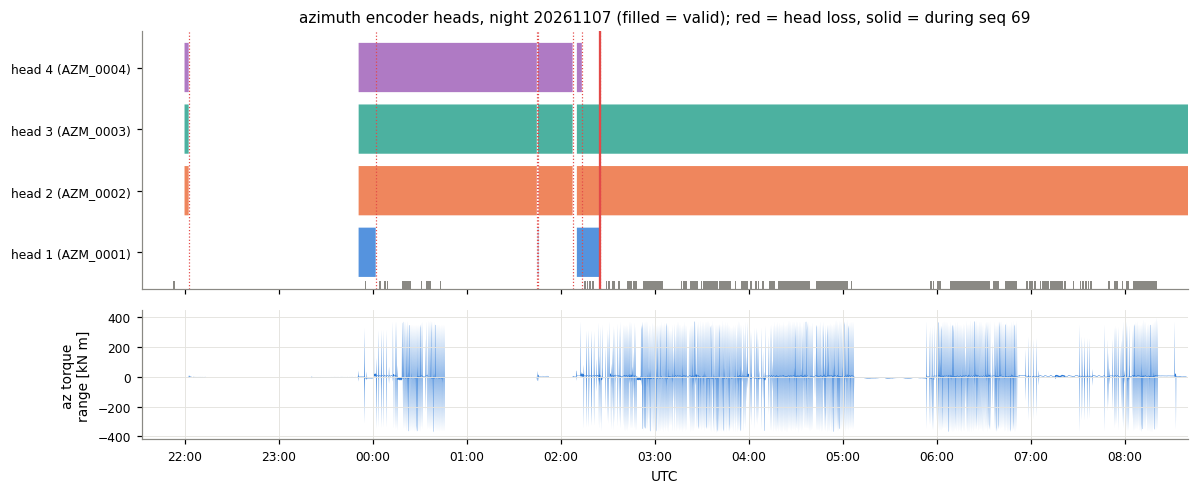

In [13]:
fig, ax = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for i in range(4):
    s = st[i]
    ax[0].fill_between(s.index, i, i + 0.8 * s.astype(int), step="post", color=C6[i], alpha=0.8, lw=0)
ax[0].set_yticks(np.arange(4) + 0.4, [HEAD_LABEL[i] for i in range(4)]); ax[0].grid(False)
for t0_, t1_ in zip(nexp.t0, nexp.t1):
    ax[0].axvspan(t0_, t1_, ymin=0, ymax=0.03, color=C_GRAY, lw=0)
for t_ in summ.t[summ.what == "LOST"]:
    ax[0].axvline(t_, color=C_FAULT, lw=0.8, ls=":")
ax[0].axvline(LOSS, color=C_FAULT, lw=1.5)
ax[0].set_title(f"azimuth encoder heads, night {DAY_OBS} (filled = valid); red = head loss, solid = during seq {SEQ}")
tq = ntq.resample("10s").agg({"tmax": "max", "tmin": "min"})
ax[1].fill_between(tq.index, tq.tmin / 1e3, tq.tmax / 1e3, color=C_AZ, lw=0)
ax[1].set_ylabel("az torque\nrange [kN m]")
fmt_t(ax[1], "%H:%M"); ax[1].set_xlabel("UTC")
ax[1].set_xlim(nexp.t0.min() - pd.Timedelta("20min"), nexp.t1.max() + pd.Timedelta("20min"))
plt.tight_layout(); plt.show()

## 7. History — every azimuth encoder-head loss since 2025-04

`MTMount.logevent_warning` codes 714–717 (one per azimuth head, `active=True`), republishes within 2 s collapsed.
For each one the build script cached ±3 s of `MTMount.azimuth` and the four read references, so each warning can be
classified:

* **real** — the head's read reference was non-zero before and zero after (otherwise the warning is a republish of an
  already-lost head, e.g. after a CSC restart);
* **heads before** — how many azimuth heads were valid just before;
* **axis state** — from |velocity| in the 2.7 s before: stopped (median < 1e-4 °/s), tracking (max < 0.15 °/s),
  settling (median < 0.1 °/s but a slew ended inside the window) or slewing;
* **kick** — peak |Δ torque| from the pre-event median within −0.3…+1 s; **jump** — peak |actual − demand| in the
  same interval (≈ the step in the head-averaged position, before the servo nulls it — only meaningful while tracking);
* **in exposure** — whether the warning falls inside an LSSTCam exposure (ConsDB, TAI → UTC).

In [14]:
waz = pd.read_parquet(DATA / "azenc_hist_windows_az.parquet")
wref = pd.read_parquet(DATA / "azenc_hist_windows_ref.parquet")
hexp = pd.read_parquet(DATA / "azenc_hist_exposures.parquet")
hql = pd.read_parquet(DATA / "azenc_hist_quicklook.parquet")
hexp["t0"], hexp["t1"] = tai2utc(hexp.obs_start), tai2utc(hexp.obs_end)
hexp = hexp.sort_values("t0").reset_index(drop=True)
REFC = [f"encoderHeadReadReferenceAZ{i}" for i in range(4)]

rows = []
for (t_, code_), g in waz.groupby(["event_time", "event_code"]):
    if code_ not in AZ_HEAD:
        continue
    h = AZ_HEAD[code_]
    r = wref[wref.event_time == t_]
    pre_r, post_r = r[r.index < t_ - pd.Timedelta("0.1s")], r[r.index > t_ + pd.Timedelta("0.1s")]
    real = len(pre_r) > 0 and len(post_r) > 0 and (pre_r[REFC[h]] != 0).any() and not (post_r[REFC[h]] != 0).any()
    n_before = int((pre_r.iloc[-1][REFC] != 0).sum()) if len(pre_r) else np.nan
    gp = g[g.index < t_ - pd.Timedelta("0.3s")]
    gq = g[(g.index > t_ - pd.Timedelta("0.3s")) & (g.index < t_ + pd.Timedelta("1s"))]
    if gp.empty or gq.empty:
        continue
    vel = gp.actualVelocity.abs().median()
    vmax_pre = gp.actualVelocity.abs().max()
    p = np.searchsorted(hexp.t0.values, np.datetime64(t_.tz_convert(None)), side="right") - 1
    inexp = p >= 0 and t_ <= hexp.t1.iloc[p]
    rows.append(dict(t=t_, head=h + 1, real=real, heads_before=n_before, vel=vel, vmax_pre=vmax_pre,
                     kick_kNm=(gq.actualTorque - gp.actualTorque.median()).abs().max() / 1e3,
                     jump_as=(gq.actualPosition - gq.demandPosition).abs().max() * 3600,
                     in_exposure=inexp, exposure_id=int(hexp.exposure_id.iloc[p]) if inexp else -1,
                     img_type=hexp.img_type.iloc[p] if inexp else "",
                     t_into_exp=(t_ - hexp.t0.iloc[p]).total_seconds() if inexp else np.nan))
H = pd.DataFrame(rows)
H["state"] = np.select([H.vel < 1e-4, H.vmax_pre < 0.15, H.vel < 0.1], ["stopped", "tracking", "settling"], "slewing")
H["era"] = np.where(H.t < pd.Timestamp("2026-05-31T12:00Z"), "2025-04 … 2026-05", "2026-06 …")
print(f"{len(H)} azimuth head-loss warnings with mount data; real drop-outs: {H.real.sum()}")
display(pd.crosstab([H.real, H.state], H["head"], margins=True))

733 azimuth head-loss warnings with mount data; real drop-outs: 577


head              1   2   3    4  All
real  state                          
False settling    1   0   0    4    5
      slewing    17   2   1   15   35
      stopped    21   1   8   15   45
      tracking   16  11  17   27   71
True  settling   12   1   4   20   37
      slewing   166  42  29  218  455
      tracking   18   1   4   62   85
All             251  58  63  361  733

Real losses while tracking — kick and position jump by era and heads left:


n  kick_median_kNm  kick_max_kNm  jump_median_as  jump_max_as
era               heads_before                                                                
2025-04 … 2026-05 3             10             1.85          4.55            0.02         1.70
                  4             57             1.87        198.37            0.03       622.69
2026-06 …         3              8            85.43        350.62            3.26       434.76
                  4             10            79.38        378.65            3.57       742.43

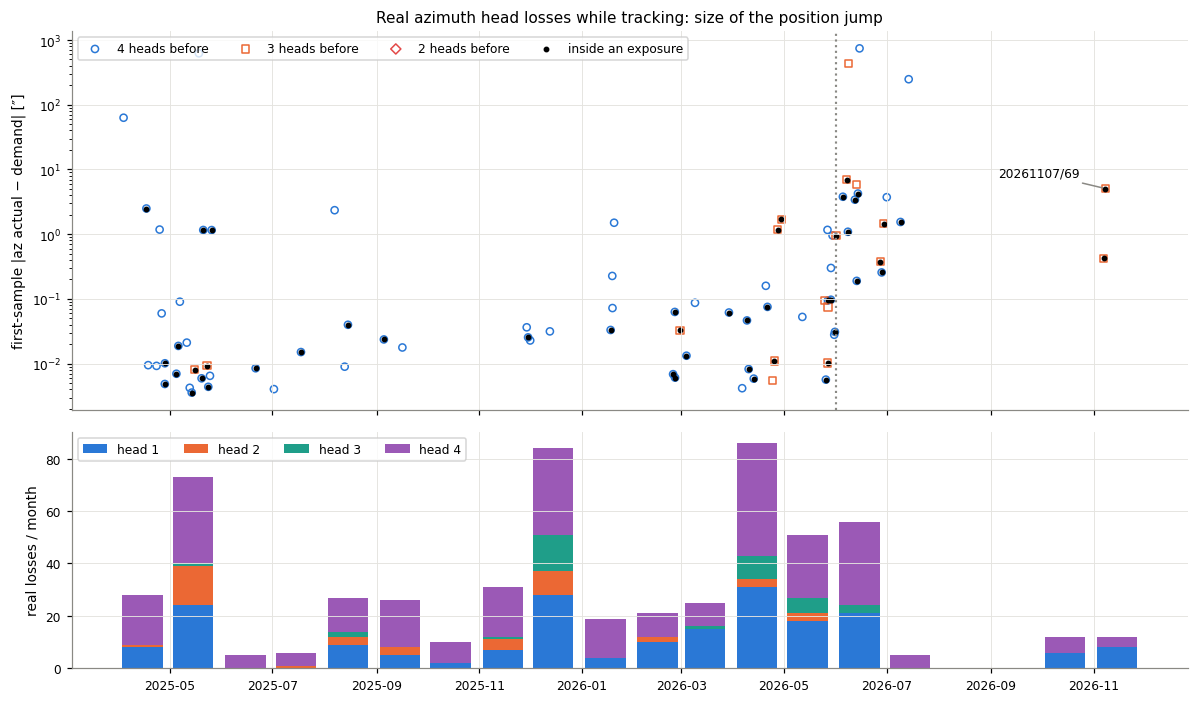

In [15]:
trk = H[H.real & (H.state == "tracking")]
print("Real losses while tracking — kick and position jump by era and heads left:")
display(trk.groupby(["era", "heads_before"]).agg(n=("t", "size"), kick_median_kNm=("kick_kNm", "median"),
        kick_max_kNm=("kick_kNm", "max"), jump_median_as=("jump_as", "median"), jump_max_as=("jump_as", "max")).round(2))

fig, ax = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw=dict(height_ratios=[1.6, 1]))
for nb, mk in ((4, "o"), (3, "s"), (2, "D")):
    s = trk[trk.heads_before == nb]
    ax[0].scatter(s.t, s.jump_as.clip(lower=3e-3), s=22, marker=mk, facecolor="none",
                  edgecolor=C_AZ if nb == 4 else C_EL if nb == 3 else C_FAULT, label=f"{nb} heads before")
s = trk[trk.in_exposure]
ax[0].scatter(s.t, s.jump_as.clip(lower=3e-3), s=8, color="k", label="inside an exposure")
me = trk.loc[(trk.t - LOSS).abs().idxmin()]
ax[0].annotate(f"{DAY_OBS}/{SEQ}", (me.t, me.jump_as), xytext=(-70, 8), textcoords="offset points",
               arrowprops=dict(arrowstyle="-", color=C_GRAY), fontsize=8)
ax[0].set_yscale("log"); ax[0].set_ylabel("first-sample |az actual − demand| [″]")
ax[0].legend(loc="upper left", ncol=4); ax[0].axvline(pd.Timestamp("2026-06-01", tz="UTC"), color=C_GRAY, ls=":")
ax[0].set_title("Real azimuth head losses while tracking: size of the position jump")
mon = H[H.real].assign(m=H.t.dt.tz_convert(None).dt.to_period("M").dt.to_timestamp()).pivot_table(
    index="m", columns="head", values="t", aggfunc="size", fill_value=0)
bottom = np.zeros(len(mon))
for hd in mon.columns:
    ax[1].bar(mon.index.tz_localize("UTC") + pd.Timedelta("14D"), mon[hd], width=24, bottom=bottom, color=C6[hd - 1], label=f"head {hd}")
    bottom += mon[hd].to_numpy()
ax[1].set_ylabel("real losses / month"); ax[1].legend(ncol=4, loc="upper left")
ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout(); plt.show()

Points above ~10″ are losses caught during small offsets / end-of-slew transients that the velocity classifier still
calls "tracking"; the population that matters is the cluster at 0.003–0.1″ before June 2026 versus 0.2–7″ after.
There was no LSSTCam science observing in Aug–Sep 2026 (and only 9 nights in July), hence no losses then.

### Image impact of losses inside exposures

For each real loss inside an LSSTCam exposure: the mount jump, guider azimuth drift, PSF ellipticity (from the median
PSF moments) and number of PSF stars, compared with the median of the ±2 neighbouring exposures. Rows are flagged
**affected** when the position jump is ≥ 0.5″ (the mechanism); `guider confirms` marks |guider azimuth drift| > 0.5″
(neighbours ~0.1″). Guider metrics exist only from late 2025.

In [16]:
q = hql.drop_duplicates("exposure_id").set_index("exposure_id")
q["psf_e"] = np.hypot(q.psf_ixx_median - q.psf_iyy_median, 2 * q.psf_ixy_median) / (q.psf_ixx_median + q.psf_iyy_median)
ie = H[H.real & H.in_exposure].sort_values("t")
out = []
for _, r in ie.iterrows():
    e = r.exposure_id
    nb = [e + d for d in (-2, -1, 1, 2) if e + d in q.index]
    me, nq = q.loc[e] if e in q.index else None, q.loc[nb]
    out.append({"t (UTC)": r.t.strftime("%Y-%m-%d %H:%M:%S"), "exposure": f"{e // 100000}/{e % 100000}", "img_type": r.img_type,
                "t into exp [s]": r.t_into_exp, "state": r.state, "heads before": r.heads_before,
                "kick [kN m]": r.kick_kNm, "jump [″]": r.jump_as,
                "guider az drift [″]": np.nan if me is None else me.guider_azimuth_drift,
                "nbr |az drift| [″]": nq.guider_azimuth_drift.abs().median(),
                "PSF e": np.nan if me is None else me.psf_e, "nbr PSF e": nq.psf_e.median(),
                "PSF stars": np.nan if me is None else me.n_psf_star_median, "nbr PSF stars": nq.n_psf_star_median.median()})
IE = pd.DataFrame(out)
IE["affected"] = IE["jump [″]"] >= 0.5
IE["guider confirms"] = IE["guider az drift [″]"].abs() > 0.5
print(f"real losses inside exposures: {len(IE)} ({(IE.img_type == 'science').sum()} science); "
      f"affected (jump ≥ 0.5″): {IE.affected.sum()}")
IE["since 2026-06"] = IE["t (UTC)"] >= "2026-06-01"
display(pd.crosstab(IE["since 2026-06"], [IE.affected, IE["guider confirms"]]))
display(IE.round(2).style.apply(lambda r: ["background-color:#fbe3e2" if r.affected else "" for _ in r], axis=1))

real losses inside exposures: 51 (38 science); affected (jump ≥ 0.5″): 15


affected        False       True       
guider confirms False True  False True 
since 2026-06                          
False              30     2     6     0
True                4     0     1     8

,t (UTC),exposure,img_type,t into exp [s],state,heads before,kick [kN m],jump [″],guider az drift [″],nbr |az drift| [″],PSF e,nbr PSF e,PSF stars,nbr PSF stars,affected,guider confirms,since 2026-06
0,2025-04-17 04:56:52,20250416/463,acq,20.250000,tracking,4,1.790000,2.500000,nan,nan,nan,nan,nan,nan,True,False,False
1,2025-04-28 03:56:13,20250427/352,science,35.920000,tracking,4,1.770000,0.000000,nan,nan,0.020000,0.060000,0.000000,0.000000,False,False,False
2,2025-04-28 05:14:33,20250427/415,acq,21.540000,tracking,4,1.920000,0.010000,nan,nan,0.320000,0.260000,55.000000,28.000000,False,False,False
3,2025-05-05 00:58:03,20250504/250,acq,3.710000,tracking,4,1.750000,0.010000,nan,nan,0.050000,0.080000,114.000000,114.500000,False,False,False
4,2025-05-06 04:26:35,20250505/385,cwfs,30.540000,tracking,4,2.170000,0.020000,nan,nan,nan,0.050000,nan,102.000000,False,False,False
5,2025-05-11 05:33:27,20250510/816,dark,1.330000,slewing,3,36.370000,126.020000,nan,nan,nan,nan,nan,nan,True,False,False
6,2025-05-14 03:24:23,20250513/223,acq,30.330000,tracking,4,0.990000,0.000000,nan,nan,0.180000,0.130000,34.000000,34.000000,False,False,False
7,2025-05-16 00:39:07,20250515/93,acq,24.170000,tracking,3,1.350000,0.010000,nan,nan,0.230000,0.120000,48.000000,45.500000,False,False,False
8,2025-05-19 23:59:32,20250519/142,acq,13.950000,tracking,4,1.260000,0.010000,nan,nan,0.530000,0.350000,0.000000,17.000000,False,False,False
9,2025-05-20 23:56:10,20250520/111,science,16.710000,tracking,4,1.600000,1.160000,nan,nan,0.290000,0.260000,38.000000,38.000000,True,False,False


## 8. Conclusions and suggested actions

* **Mechanism.** The azimuth position is a mean over the heads that currently have a valid read reference. When a head
  drops out, the mean changes by (offset of that head from the others) / (number of heads). For 20261107/69 that was
  ≈ 16″ / 3 ≈ 5.4″. The controller treats it as a real following error and kicks the axis. The kick reaches every
  optical element on the TMA, and it leaves a permanent azimuth offset of the same size until the next power cycle.
* **For the TMA team.**
  1. *Why did head losses become multi-arcsecond events around 2026-06-01?* Up to May 2026 the same drop-out produced
     0.01–0.1″ jumps, so either the remaining heads were re-offset bumplessly or the heads agreed after calibration. Now
     they disagree by ~10–20″ and the switch is not bumpless. Possible causes: a head re-calibration or tape
     re-installation, a change in the EIB/PLC encoder handling, or tape eccentricity growing. A bumpless head-set change
     (re-offsetting the remaining average when a head drops) would eliminate the impulse whatever the cause.
  2. *Why do heads 1 and 4 drop so often* (196 and 300 real losses) while heads 2 and 3 rarely do? Repeated drops
     within minutes of a power cycle on 20261107 suggest a hardware issue at those read heads (alignment, contamination,
     cabling) rather than random noise.
* **For operations / data quality.**
  * Treat MTMount warnings **714–717 during an exposure** as an image-quality flag. The guider azimuth drift in ConsDB
    confirms the damage. This could be a Watcher rule or a RubinTV annotation.
  * Running on two heads (most of 20261107 and all of 20261108) leaves no redundancy, and the next drop-out produces
    the biggest step. Consider power-cycling azimuth at the next convenient break rather than at the end of the night.
  * The affected exposures since June 2026 are listed in §7 (`IE[IE.affected]`) and should be noted in the exposure log.
* **Reproduce.** `python3 -E build_az_encoder_headloss.py` (≈ 5 min; `--skip-history` for the event and night only),
  then run this notebook.